### Other Company Data

In this notebook, you will learn to fetch other company data. The following data are fetched using the yfinance package:
1. Earnings Calendar
2. Corporate Actions


In [1]:
# Import the yfinance library
import yfinance as yf

# Import data manipulation library
import pandas as pd

# Import matplotlib and set the style for plotting
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Import time manipulation library
from datetime import timedelta

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

### Define the Stock Ticker
Define the stock ticker whose data will be fetched.

In [2]:
# Define the asset ticker for the company
stock_ticker_symbol = 'AAPL'
stock_ticker = yf.Ticker(stock_ticker_symbol)

### Earnings Calendar
Earnings dates helps us understand the schedule according to which various publicly-traded companies announce their earnings for a certain period such as a quarter or a year.

In [3]:
# Fetch the earnings calendar of the stock and store it in a DataFrame
earnings_dates = stock_ticker.get_earnings_dates()

# Drop the NaN values
earnings_dates.dropna(inplace=True)

# Print the last 5 rows
earnings_dates.head()

,EPS Estimate,Reported EPS,Surprise(%)
Earnings Date,,,
2026-07-30 16:00:00-04:00,1.89,2.02,6.74
2026-04-30 16:00:00-04:00,1.94,2.01,3.46
2026-01-29 16:00:00-05:00,2.67,2.84,6.25
2025-10-30 16:00:00-04:00,1.77,1.85,4.52
2025-07-31 16:00:00-04:00,1.43,1.57,9.48


### Corporate Actions
A corporate action is any activity that a company does which brings material impact to its stakeholders. Common corporate actions include the payment of dividends and stock splits.

Dividends are the distribution of a company's earnings to its shareholders. A stock split is an action by which the number of shares of a company is increased by a specified multiple, while the share price is decreased by the same factor as the multiple.

Last 12 corporate actions 
                           Dividends  Stock Splits
Date                                              
2023-11-10 00:00:00-05:00       0.24           0.0
2024-02-09 00:00:00-05:00       0.24           0.0
2024-05-10 00:00:00-04:00       0.25           0.0
2024-08-12 00:00:00-04:00       0.25           0.0
2024-11-08 00:00:00-05:00       0.25           0.0
2025-02-10 00:00:00-05:00       0.25           0.0
2025-05-12 00:00:00-04:00       0.26           0.0
2025-08-11 00:00:00-04:00       0.26           0.0
2025-11-10 00:00:00-05:00       0.26           0.0
2026-02-09 00:00:00-05:00       0.26           0.0
2026-05-11 00:00:00-04:00       0.27           0.0
2026-08-10 00:00:00-04:00       0.27           0.0


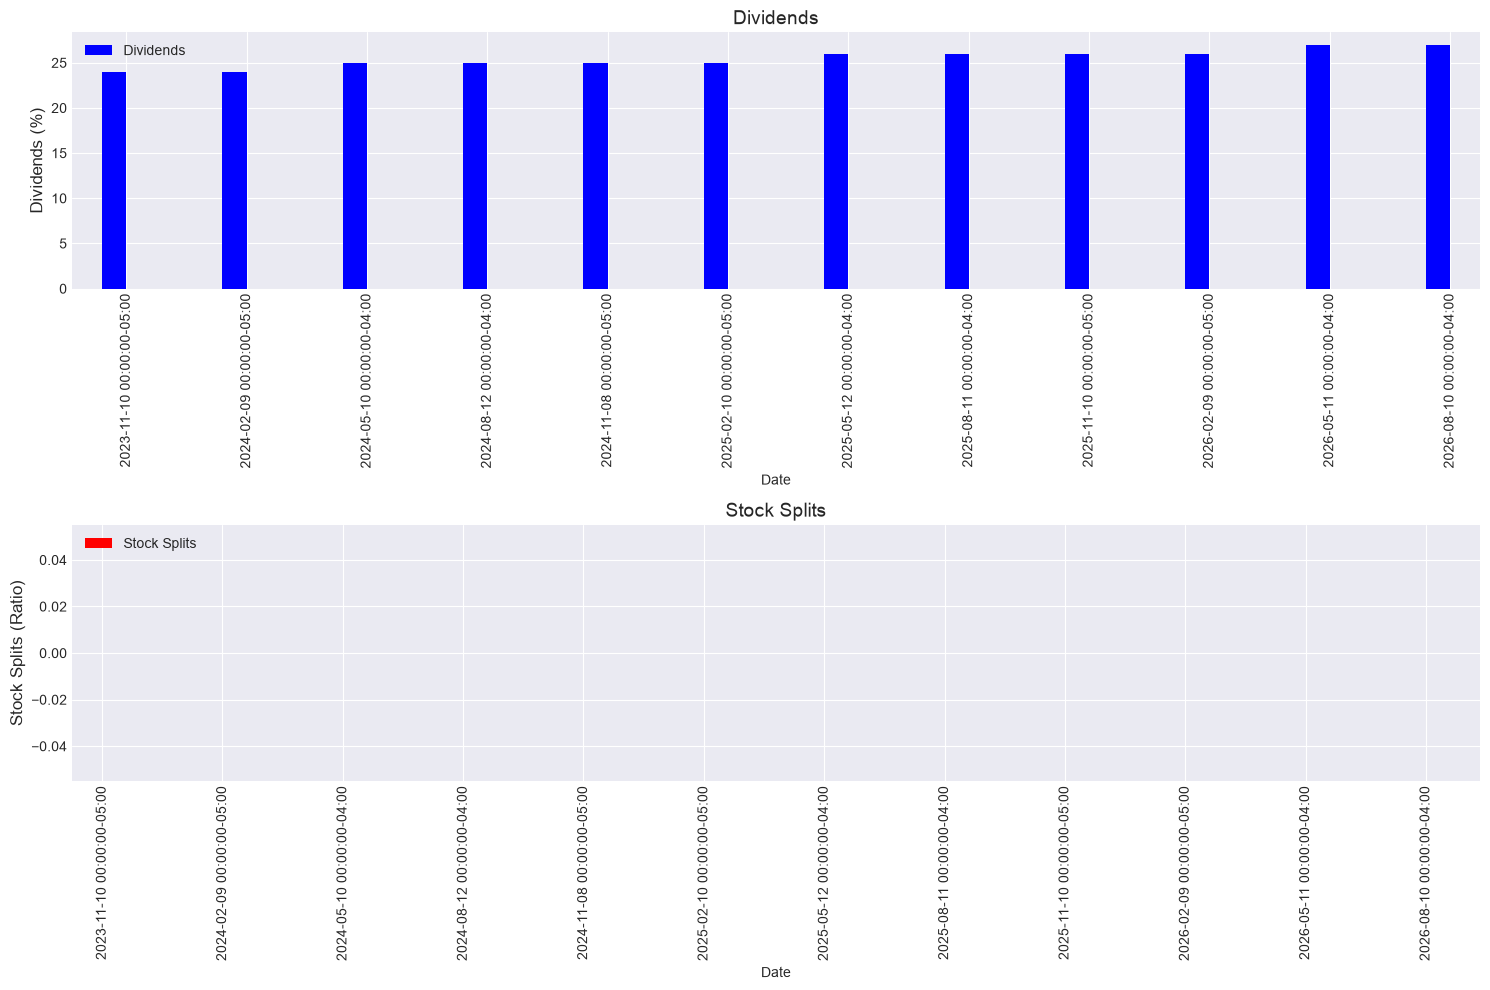

In [5]:
# Corporate actions
corporate_actions = stock_ticker.get_actions()

# Print the last 10 corporate actions
print(f"Last 12 corporate actions \n{corporate_actions.tail(12)}")

# Plot the net income and revenue for the last 3 years
data_to_plot = corporate_actions.tail(12)

# Define the plot figure
fig = plt.figure(figsize=(15, 10))
ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212)
width = 0.2

# Plot the data
(data_to_plot['Dividends'] * 100).plot(kind='bar', color='blue', ax=ax1, width=width, position=1)
data_to_plot['Stock Splits'].plot(kind='bar', color='red', ax=ax2, width=width, position=0)

# Set title and labels for the plot
ax1.set_ylabel('Dividends (%)', fontsize=12)
ax2.set_ylabel('Stock Splits (Ratio)', fontsize=12)
ax1.set_title('Dividends', fontsize=14)
ax2.set_title('Stock Splits', fontsize=14)
ax1.legend(loc=2)
ax2.legend(loc=2)
plt.tight_layout()
plt.show()